# 🛒 Case Study 59: E-Commerce Cart Abandonment (Session Non-Purchase) Analysis
**Academic Domain:** Machine Learning | B.Tech CSE Semester V (ITM Skills University)  
**Dataset:** UCI Online Shoppers Purchasing Intention Dataset (12,205 deduplicated e-commerce sessions)

---
### 📌 Executive Summary & Project Objective for Faculty Presentation
1. **Problem Framing:** Predict whether an online session ends in **abandonment (non-purchase)** vs purchase using session-level clickstream behavior.
2. **Operational Dual-Model Architecture:**
   - **Early-Session Model (No ):** Predicts risk early during live browsing before basket totals are calculated.
   - **Full Model (With ):** Evaluates risk at final checkout.
3. **Cost-Optimal Thresholding (^*$):** Optimizes classification decision boundaries under asymmetric financial costs ({FP} = \.00$ discount vs {FN} = \.00$ lost margin).
4. **Behavioral Segmentation:** Applies 569XMeans (=3$) on log-transformed metrics of abandoners to define actionable personas (*Light Browsers*, *Bouncers*, *Deep Browsers*).

In [1]:
# Import system, warning, and json libraries
import os, json, warnings
warnings.filterwarnings('ignore')

# Import core data analysis libraries
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Import scikit-learn model evaluation and pipeline tools
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
                             make_scorer, silhouette_score)

# Import machine learning classification and clustering algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Import imbalanced-learn pipeline and SMOTE oversampling
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Import SHAP model explainability library
import shap

# Set global random seed and plot styling parameters
SEED = 67
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110

# Define robust project root directory finder function
def find_root():
    try:
        curr = os.path.abspath(os.getcwd())
    except Exception:
        curr = os.path.abspath(os.path.expanduser('~/Desktop'))
    
    for _ in range(6):
        for candidate in [curr, os.path.join(curr, 'cart-abandonment')]:
            target = os.path.join(candidate, 'data', 'raw', 'online_shoppers_intention.csv')
            if os.path.exists(target):
                try:
                    os.chdir(candidate)
                except Exception:
                    pass
                return os.path.abspath(candidate)
        curr = os.path.dirname(curr)
    
    for path in [
        '/Users/atharvakalekar/Desktop/ML FINAL /cart-abandonment',
        '/Users/atharvakalekar/Desktop/ML FINAL ',
        os.path.abspath(os.path.expanduser('~/Desktop/ML FINAL /cart-abandonment'))
    ]:
        if os.path.exists(os.path.join(path, 'data', 'raw', 'online_shoppers_intention.csv')):
            try:
                os.chdir(path)
            except Exception:
                pass
            return os.path.abspath(path)
    raise FileNotFoundError("Put online_shoppers_intention.csv in <project>/data/raw/ (download: UCI dataset id 468).")

# Initialize output folder directories for models, reports, and figures
ROOT = find_root()
MODELS_DIR  = os.path.join(ROOT, 'models')
REPORTS_DIR = os.path.join(ROOT, 'reports')
FIG_DIR     = os.path.join(REPORTS_DIR, 'figures')
for d in (MODELS_DIR, REPORTS_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

# Helper function to save generated plots to disk
def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches='tight')

print("Project root:", ROOT)


Project root: /Users/atharvakalekar/Desktop/ML FINAL /cart-abandonment


## 2. Data Loading, Quality Audit & Deduplication
> **Faculty Explanation Note:**
> Data integrity is established first. We load the 12,330 raw session logs, perform missing value checks, and identify 125 exact duplicate sessions. Removing duplicates prevents synthetic data inflation and ensures non-biased cross-validation splits.

In [2]:
# Load raw e-commerce session dataset from CSV file
raw_df = pd.read_csv(os.path.join(ROOT, 'data', 'raw', 'online_shoppers_intention.csv'))
print("Raw shape:", raw_df.shape)

# Check dataset for null or missing values across columns
print("Missing values:", raw_df.isnull().sum().sum())

# Identify and count exact duplicate session rows
n_dup = raw_df.duplicated().sum()
print(f"Exact duplicates: {n_dup} ({n_dup/len(raw_df)*100:.2f}%)")

# Remove duplicate rows to ensure clean dataset integrity
df = raw_df.drop_duplicates().reset_index(drop=True)

# Create binary target variable: 1 for Abandoned (Revenue=False), 0 for Purchased
df['Is_Abandoned'] = (df['Revenue'] == False).astype(int)

# Compute baseline cart abandonment rate percentage
base_abandonment_rate = df['Is_Abandoned'].mean()
print(f"Deduplicated shape: {df.shape}")
print(f"Base abandonment rate: {base_abandonment_rate*100:.2f}%")


Raw shape: (12330, 18)
Missing values: 0
Exact duplicates: 125 (1.01%)
Deduplicated shape: (12205, 19)
Base abandonment rate: 84.37%


## 3. Exploratory Data Analysis (EDA) & Domain Insights
> **Faculty Explanation Note:**
> EDA reveals two key domain properties:
> 1. **Class Imbalance:** 84.37% abandoners vs 15.63% buyers. Accuracy alone is misleading, requiring Macro F1, PR-AUC, and F1-Purchaser metrics.
> 2. ** Proxy Leakage:**  is near-zero for non-buyers and positive for buyers. To enable real-time prediction early in a session, we build an ablated model excluding .

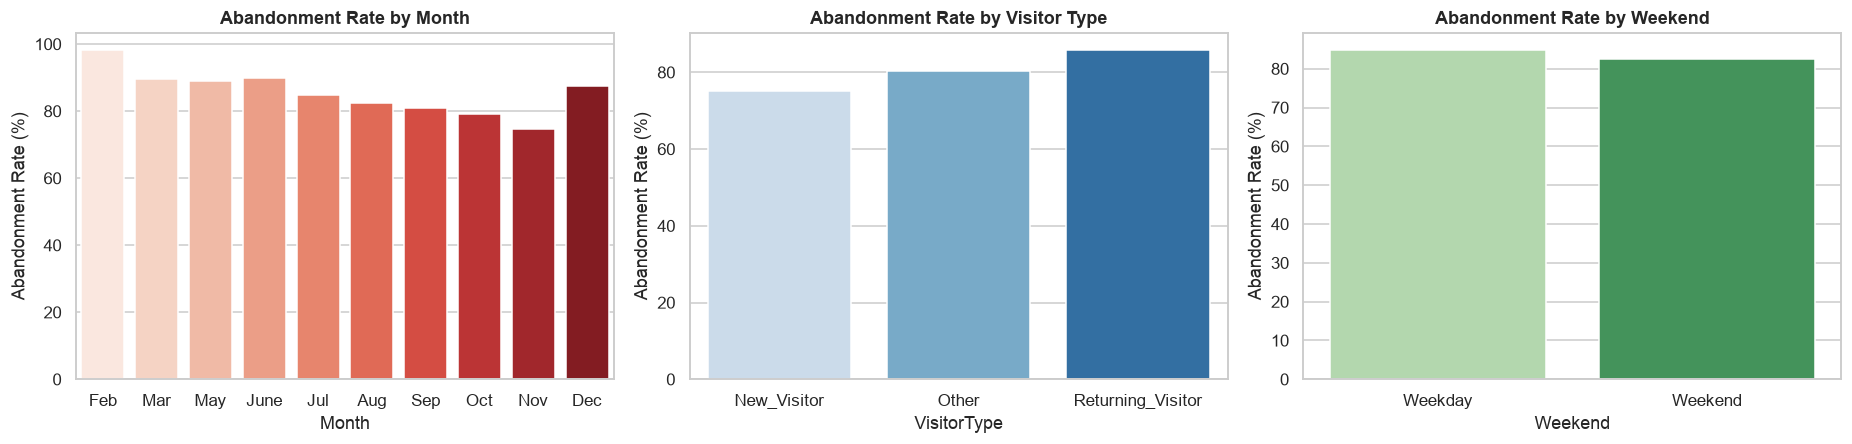

In [3]:
# Sort unique calendar months chronologically
month_order = [m for m in ['Feb','Mar','May','June','Jul','Aug','Sep','Oct','Nov','Dec'] if m in df['Month'].unique()]

# Calculate abandonment rate and session count grouped by month
m_df = df.groupby('Month')['Is_Abandoned'].agg(['mean', 'size']).reindex(month_order).reset_index()
m_df['Abandonment Rate (%)'] = m_df['mean'] * 100

# Create bar plot showing monthly cart abandonment rates
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.barplot(data=m_df, x='Month', y='Abandonment Rate (%)', palette='Reds', ax=axes[0])
axes[0].set_title('Abandonment Rate by Month', weight='bold')

# Create bar plot showing abandonment rate by visitor type
v_df = df.groupby('VisitorType')['Is_Abandoned'].mean().mul(100).reset_index(name='Abandonment Rate (%)')
sns.barplot(data=v_df, x='VisitorType', y='Abandonment Rate (%)', palette='Blues', ax=axes[1])
axes[1].set_title('Abandonment Rate by Visitor Type', weight='bold')

# Create bar plot showing abandonment rate on weekends vs weekdays
w_df = df.groupby('Weekend')['Is_Abandoned'].mean().mul(100).reset_index(name='Abandonment Rate (%)')
w_df['Weekend'] = w_df['Weekend'].map({True: 'Weekend', False: 'Weekday'})
sns.barplot(data=w_df, x='Weekend', y='Abandonment Rate (%)', palette='Greens', ax=axes[2])
axes[2].set_title('Abandonment Rate by Weekend', weight='bold')

plt.tight_layout()
savefig('01_eda_categorical.png')
plt.show()


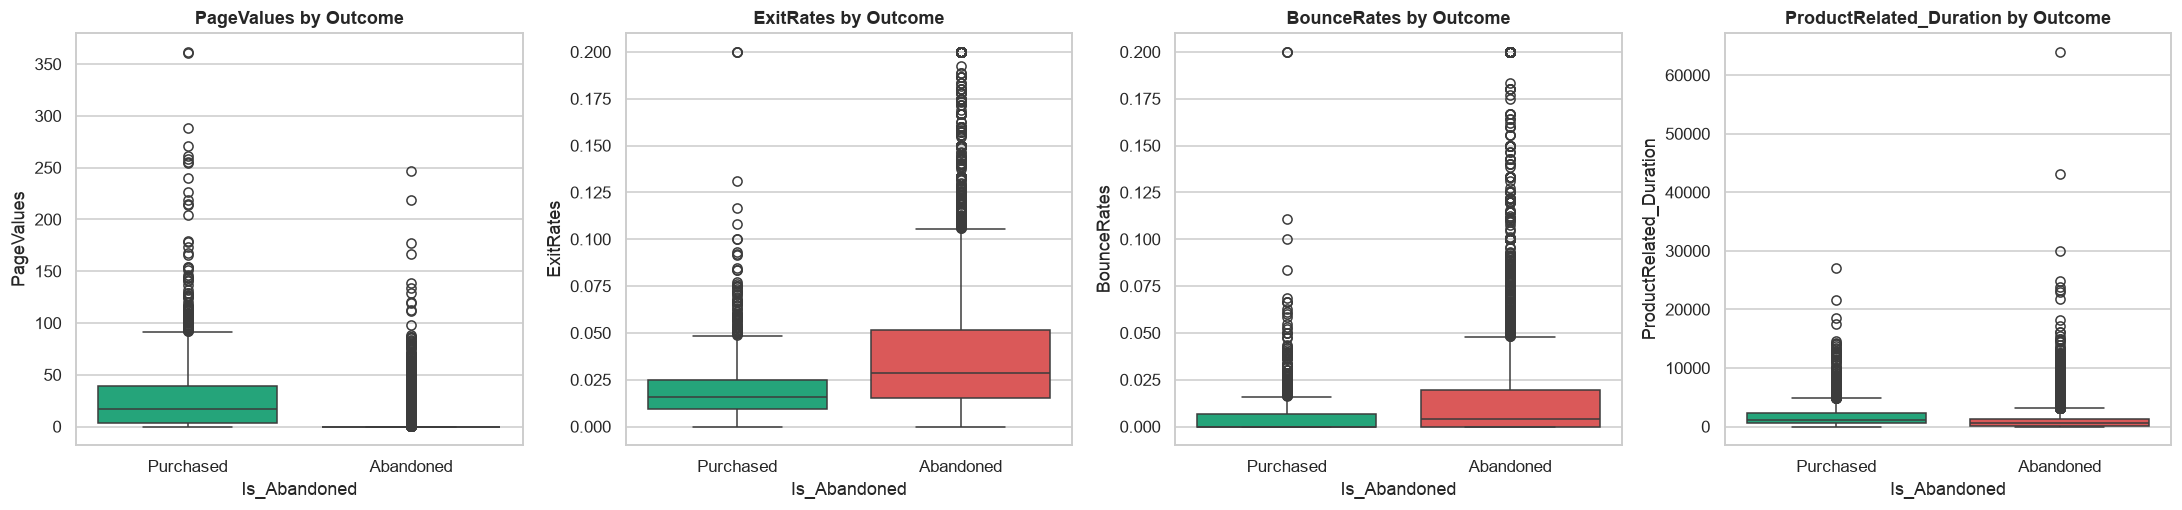

In [4]:
# Create box plots comparing key behavioral metrics between abandoners and buyers
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for ax, col in zip(axes, ['PageValues', 'ExitRates', 'BounceRates', 'ProductRelated_Duration']):
    sns.boxplot(data=df, x='Is_Abandoned', y=col, ax=ax, palette=['#10b981', '#ef4444'])
    ax.set_xticklabels(['Purchased', 'Abandoned'])
    ax.set_title(f'{col} by Outcome', weight='bold')

plt.tight_layout()
savefig('02_eda_boxplots.png')
plt.show()


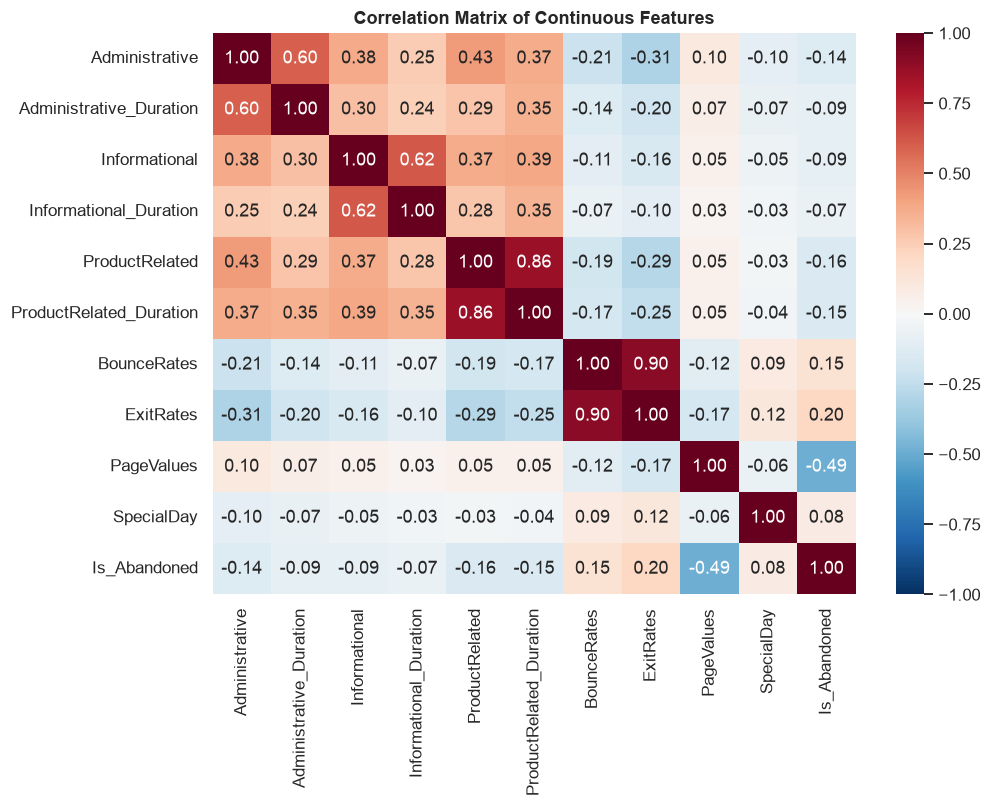

In [5]:
# Select continuous numerical columns for correlation analysis
num_cols_corr = ['Administrative','Administrative_Duration','Informational','Informational_Duration','ProductRelated',
                 'ProductRelated_Duration','BounceRates','ExitRates','PageValues','SpecialDay','Is_Abandoned']

# Compute Pearson correlation matrix across numerical features
corr = df[num_cols_corr].corr()

# Plot correlation heatmap showing feature relationships and target correlation
plt.figure(figsize=(9.5, 7.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Continuous Features', weight='bold')
plt.tight_layout()
savefig('03_correlation_matrix.png')
plt.show()


## 4. Leak-Free Preprocessing Pipeline Architecture
> **Faculty Explanation Note:**
> We use Scikit-Learn  inside  objects to prevent data leakage:
> - **Numerical Features:** Standardized using  ( = (x - \mu) / \sigma$).
> - **Categorical Features:** One-Hot Encoded (, , ).
> - **Zero-Leakage Guarantee:** Scalers and encoders fit *only* on training folds, never on held-out test data.

In [6]:
# Define full numerical feature column list
numeric_full = ['Administrative','Administrative_Duration','Informational','Informational_Duration',
                'ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','PageValues','SpecialDay',
                'OperatingSystems','Browser','Region','TrafficType']

# Define categorical feature column list
categorical  = ['Month', 'VisitorType', 'Weekend']

# Helper function to construct preprocessor with StandardScaler and OneHotEncoder
def make_preprocessor(num_cols):
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical)
    ])


## 5. Model Development & Rigorous Benchmarking
> **Faculty Explanation Note:**
> We benchmark 5 distinct ML algorithms (Logistic Regression, KNN, Decision Tree, Random Forest, HistGradientBoosting) across 3 experimental conditions to justify our final model choice based on empirical evidence.

In [7]:
# Initialize dictionary of 5 machine learning baseline models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=SEED),
    'KNN':                 KNeighborsClassifier(n_neighbors=5),
    'Decision Tree':       DecisionTreeClassifier(random_state=SEED),
    'Random Forest':       RandomForestClassifier(random_state=SEED, max_depth=12),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=SEED)
}


### 5.1 Stage 1: Baseline Classifiers (Full Features, Default =0.5$)
*Evaluates default classifier performance on held-out test set using all original features.*

In [8]:
# Helper function to calculate comprehensive evaluation metrics for model predictions
def eval_dict(y_true, prob, t=0.5):
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        'Accuracy (%)':          accuracy_score(y_true, pred) * 100,
        'Precision (%)':         precision_score(y_true, pred, pos_label=1, zero_division=0) * 100,
        'Recall (%)':            recall_score(y_true, pred, pos_label=1, zero_division=0) * 100,
        'Abandoner F1 (%)':      f1_score(y_true, pred, pos_label=1, zero_division=0) * 100,
        'Purchaser F1 (%)':      f1_score(y_true, pred, pos_label=0, zero_division=0) * 100,
        'Macro F1 (%)':          f1_score(y_true, pred, average='macro', zero_division=0) * 100,
        'ROC-AUC':               roc_auc_score(y_true, prob),
        'PR-AUC (Purchaser)':    average_precision_score(1 - y_true, 1 - prob),
        'FPR (%)':               (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0,
        'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp
    }

# Create train-test split (80% train, 20% test) with stratified class distribution
feature_cols_all = numeric_full + categorical
X = df[feature_cols_all]
y = df['Is_Abandoned']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

# Store all experiment leaderboard results in a list
experiment_rows = []

# Evaluate baseline models on held-out test set using full features
for name, model in models.items():
    pipe = Pipeline([('preprocessor', make_preprocessor(numeric_full)), ('model', clone(model))])
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]
    m = eval_dict(y_test, prob, t=0.5)
    row = {'Stage': '1. Baseline, full features', 'Evaluation': 'Test (t=0.5)', 'Algorithm': name}
    row.update(m)
    experiment_rows.append(row)

# Display baseline model results summary table
display(pd.DataFrame(experiment_rows).drop(columns=['tn','fp','fn','tp']))


,Stage,Evaluation,Algorithm,Accuracy (%),Precision (%),Recall (%),Abandoner F1 (%),Purchaser F1 (%),Macro F1 (%),ROC-AUC,PR-AUC (Purchaser),FPR (%)
0,"1. Baseline, full features",Test (t=0.5),Logistic Regression,87.259320,89.052726,96.794560,92.762392,46.837607,69.800000,0.899016,0.621493,64.136126
1,"1. Baseline, full features",Test (t=0.5),KNN,87.177386,89.288929,96.357455,92.688624,47.920133,70.304379,0.787166,0.477477,62.303665
2,"1. Baseline, full features",Test (t=0.5),Decision Tree,85.538714,91.772772,91.015056,91.392343,54.801536,73.096940,0.735180,0.369287,43.979058
3,"1. Baseline, full features",Test (t=0.5),Random Forest,90.045063,92.154132,96.406022,94.232139,63.677130,78.954634,0.932717,0.741198,44.240838
4,"1. Baseline, full features",Test (t=0.5),Gradient Boosting,89.512495,92.785952,94.949004,93.855017,64.245810,79.050413,0.933784,0.734817,39.790576


### 5.2 Stage 2: SMOTE Oversampling Inside 5-Fold Stratified Cross-Validation
> **CRITICAL VIVA NOTE FOR FACULTY:**
> To handle the 84:16 class imbalance without data leakage, **SMOTE is applied strictly inside each training fold** using . The validation fold remains untouched and un-sampled to measure true generalization.

In [9]:
# Initialize 5-fold stratified cross-validation splitter
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Evaluate 5 models using 5-fold CV with SMOTE oversampling applied inside training folds
for name, model in models.items():
    pipe = ImbPipeline([
        ('preprocessor', make_preprocessor(numeric_full)),
        ('smote', SMOTE(random_state=SEED)),
        ('model', clone(model))
    ])
    
    # Compute out-of-fold probability predictions
    oof_prob = cross_val_predict(pipe, X_train, y_train, cv=cv5, method='predict_proba')[:, 1]
    m = eval_dict(y_train, oof_prob, t=0.5)
    row = {'Stage': '2. SMOTE 5-fold CV, full features', 'Evaluation': 'CV mean', 'Algorithm': name}
    row.update(m)
    experiment_rows.append(row)

# Display 5-fold SMOTE CV results table
df_stage2 = pd.DataFrame(experiment_rows)
display(df_stage2[df_stage2['Stage'] == '2. SMOTE 5-fold CV, full features'].drop(columns=['tn','fp','fn','tp']))


,Stage,Evaluation,Algorithm,Accuracy (%),Precision (%),Recall (%),Abandoner F1 (%),Purchaser F1 (%),Macro F1 (%),ROC-AUC,PR-AUC (Purchaser),FPR (%)
5,"2. SMOTE 5-fold CV, full features",CV mean,Logistic Regression,85.088079,94.937715,86.962855,90.775469,61.111111,75.943290,0.900744,0.660128,25.032765
6,"2. SMOTE 5-fold CV, full features",CV mean,KNN,77.498976,93.416703,78.890507,85.541296,49.296100,67.418698,0.800032,0.413938,30.013106
7,"2. SMOTE 5-fold CV, full features",CV mean,Decision Tree,85.712823,92.849092,89.997572,91.401097,57.791225,74.596161,0.762897,0.394431,37.418087
8,"2. SMOTE 5-fold CV, full features",CV mean,Random Forest,88.979926,95.375063,91.369264,93.329200,68.334314,80.831757,0.924474,0.712828,23.918742
9,"2. SMOTE 5-fold CV, full features",CV mean,Gradient Boosting,89.389594,94.900249,92.388929,93.627752,68.318043,80.972898,0.926396,0.734607,26.802097


### 5.3 Stage 3: Feature Ablation (Early-Session Model without )
*Evaluates all 5 algorithms without  to measure real-time predictive capability early in the user journey.*

In [10]:
# Exclude PageValues to build early-session feature list
numeric_real = [c for c in numeric_full if c != 'PageValues']
X_train_real = X_train[numeric_real + categorical]
X_test_real  = X_test[numeric_real + categorical]

# Evaluate models using 5-fold SMOTE CV without PageValues
for name, model in models.items():
    pipe = ImbPipeline([
        ('preprocessor', make_preprocessor(numeric_real)),
        ('smote', SMOTE(random_state=SEED)),
        ('model', clone(model))
    ])
    oof_prob = cross_val_predict(pipe, X_train_real, y_train, cv=cv5, method='predict_proba')[:, 1]
    m = eval_dict(y_train, oof_prob, t=0.5)
    row = {'Stage': '3. SMOTE 5-fold CV, no PageValues', 'Evaluation': 'CV mean', 'Algorithm': name}
    row.update(m)
    experiment_rows.append(row)

# Evaluate models on test set without PageValues
for name, model in models.items():
    pipe = ImbPipeline([
        ('preprocessor', make_preprocessor(numeric_real)),
        ('smote', SMOTE(random_state=SEED)),
        ('model', clone(model))
    ])
    pipe.fit(X_train_real, y_train)
    prob = pipe.predict_proba(X_test_real)[:, 1]
    m = eval_dict(y_test, prob, t=0.5)
    row = {'Stage': '4. SMOTE, no PageValues', 'Evaluation': 'Test (t=0.5)', 'Algorithm': name}
    row.update(m)
    experiment_rows.append(row)

# Display ablation study results comparing CV and Test performance without PageValues
df_exp = pd.DataFrame(experiment_rows)
display(df_exp[df_exp['Stage'].str.contains('no PageValues')].drop(columns=['tn','fp','fn','tp']))


,Stage,Evaluation,Algorithm,Accuracy (%),Precision (%),Recall (%),Abandoner F1 (%),Purchaser F1 (%),Macro F1 (%),ROC-AUC,PR-AUC (Purchaser),FPR (%)
10,"3. SMOTE 5-fold CV, no PageValues",CV mean,Logistic Regression,63.191315,92.126270,61.641175,73.861818,37.798546,55.830182,0.732443,0.307847,28.440367
11,"3. SMOTE 5-fold CV, no PageValues",CV mean,KNN,64.348628,89.139378,65.756252,75.682850,33.224631,54.453740,0.656686,0.229897,43.250328
12,"3. SMOTE 5-fold CV, no PageValues",CV mean,Decision Tree,75.081934,87.302403,82.459335,84.811786,30.664007,57.737896,0.588575,0.196839,64.744430
13,"3. SMOTE 5-fold CV, no PageValues",CV mean,Random Forest,77.212208,89.193065,83.054139,86.014206,38.518928,62.266567,0.759313,0.346486,54.325033
14,"3. SMOTE 5-fold CV, no PageValues",CV mean,Gradient Boosting,81.093814,87.957245,89.900461,88.918237,35.679443,62.298840,0.758017,0.337487,66.448231
15,"4. SMOTE, no PageValues",Test (t=0.5),Logistic Regression,63.990168,92.753623,62.166100,74.440244,39.085239,56.762742,0.751338,0.337153,26.178010
16,"4. SMOTE, no PageValues",Test (t=0.5),KNN,65.219172,89.234760,66.828558,76.423216,33.723653,55.073435,0.659290,0.242004,43.455497
17,"4. SMOTE, no PageValues",Test (t=0.5),Decision Tree,75.337976,87.187340,82.952890,85.017422,30.324074,57.670748,0.586230,0.196030,65.706806
18,"4. SMOTE, no PageValues",Test (t=0.5),Random Forest,78.738222,90.145985,83.972802,86.949962,42.651934,64.800948,0.790524,0.403218,49.476440
19,"4. SMOTE, no PageValues",Test (t=0.5),Gradient Boosting,82.425236,88.155431,91.452161,89.773540,37.554585,63.664063,0.788258,0.379654,66.230366


## 6. Hyperparameter Tuning & Pipeline Optimization
> **Faculty Explanation Note:**
> Grid Search with 5-Fold Stratified CV tunes the top-performing  (learning rate, tree depth, l2 regularization) to maximize out-of-fold ROC-AUC.

In [11]:
# Define hyperparameter search grid for Gradient Boosting
param_grid = {'model__n_estimators': [100, 200], 'model__max_depth': [3, 5], 'model__learning_rate': [0.1]}

# Helper function to tune Gradient Boosting pipeline using 5-fold GridSearchCV
def tune(X_tr, y_tr, num_cols):
    pipe = ImbPipeline([
        ('preprocessor', make_preprocessor(num_cols)),
        ('smote', SMOTE(random_state=SEED)),
        ('model', GradientBoostingClassifier(random_state=SEED))
    ])
    gs = GridSearchCV(pipe, param_grid, cv=cv5, scoring='roc_auc', n_jobs=-1)
    gs.fit(X_tr, y_tr)
    return gs

# Tune early-session model (without PageValues)
gs_real = tune(X_train_real, y_train, numeric_real)

# Tune full model (with PageValues)
gs_full = tune(X_train, y_train, numeric_full)

# Display best hyperparameters found for both model variants
print("Best params (no PageValues):", gs_real.best_params_)
print("Best params (full features):", gs_full.best_params_)

# Retrieve best tuned model estimators
tuned_no_pv = gs_real.best_estimator_
tuned_full  = gs_full.best_estimator_


Best params (no PageValues): {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 100}
Best params (full features): {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}


## 7. Cost-Aware Threshold Optimization (^*$)
> **Faculty Explanation Note:**
> Standard =0.5$ fails in business because costs are asymmetric ({FP} = \$ coupon vs {FN} = \$ lost sale).
> We compute out-of-fold decision costs across  \in [0, 1]$ and select ^*$ that minimizes total business cost:
> 30108	ext{Cost}(t) = C_{FP} \cdot FP(t) + C_{FN} \cdot FN(t)30108

In [12]:
# Define business costs: False Positive (coupon discount) and False Negative (lost profit margin)
C_FP = 2.0
PRIMARY_C_FN = 1.0
FN_COSTS = [0.5, 1.0, 1.5, 2.0, 3.0, 5.0, 10.0, 25.0]

# Helper function to compute total business cost at a specified classification threshold
def cost_at(y_true, prob, t, c_fp, c_fn):
    pred = (prob >= t).astype(int)
    fp = np.sum((pred == 1) & (y_true == 0))
    fn = np.sum((pred == 0) & (y_true == 1))
    return fp * c_fp + fn * c_fn

# Compute out-of-fold predictions to tune optimal decision threshold t*
oof_no_pv = cross_val_predict(tuned_no_pv, X_train_real, y_train, cv=cv5, method='predict_proba')[:, 1]
oof_full  = cross_val_predict(tuned_full,  X_train,      y_train, cv=cv5, method='predict_proba')[:, 1]

# Helper function to sweep threshold from 0 to 1 and find threshold that minimizes cost
def find_opt_threshold(y_true, prob, c_fp, c_fn):
    ts = np.linspace(0.01, 0.99, 99)
    costs = [cost_at(y_true, prob, t, c_fp, c_fn) for t in ts]
    return ts[np.argmin(costs)], np.min(costs)

# Compute optimal operating threshold t* for both model variants
t_no_pv, _ = find_opt_threshold(y_train, oof_no_pv, C_FP, PRIMARY_C_FN)
t_full,  _ = find_opt_threshold(y_train, oof_full,  C_FP, PRIMARY_C_FN)
print(f"Optimal threshold t* (no PageValues, C_FN={PRIMARY_C_FN}): {t_no_pv:.2f}")
print(f"Optimal threshold t* (full features, C_FN={PRIMARY_C_FN}): {t_full:.2f}")


Optimal threshold t* (no PageValues, C_FN=1.0): 0.53
Optimal threshold t* (full features, C_FN=1.0): 0.47


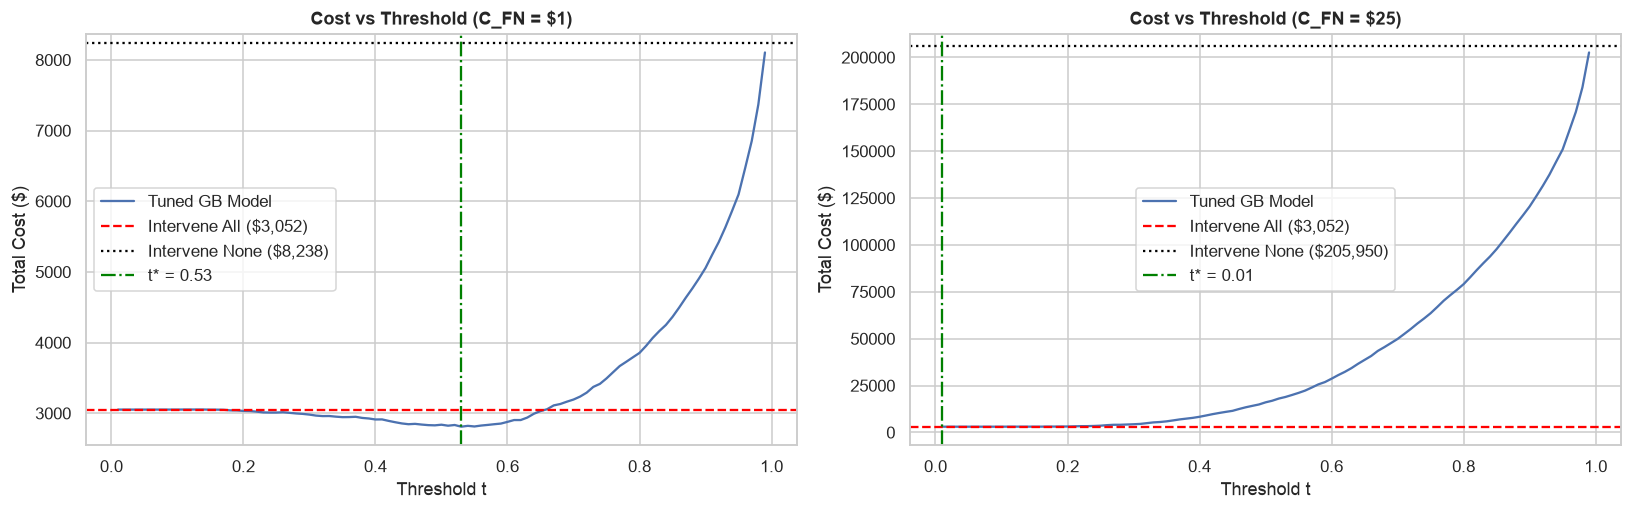

,FN Cost ($),Cost Ratio (FN:FP),Optimal t*,Model Cost ($),Best Naive Cost ($),Savings vs Best Naive (%)
0,0.5,0.2:1,0.71,2210.0,3052.0,27.59
1,1.0,0.5:1,0.53,2810.0,3052.0,7.93
2,1.5,0.8:1,0.31,2999.5,3052.0,1.72
3,2.0,1.0:1,0.23,3026.0,3052.0,0.85
4,3.0,1.5:1,0.23,3040.0,3052.0,0.39
5,5.0,2.5:1,0.01,3052.0,3052.0,0.00
6,10.0,5.0:1,0.01,3052.0,3052.0,0.00
7,25.0,12.5:1,0.01,3052.0,3052.0,0.00


In [13]:
# Plot cost vs classification threshold curves under different cost ratios
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, c_fn in zip(axes, [PRIMARY_C_FN, 25.0]):
    costs = [cost_at(y_train, oof_no_pv, t, C_FP, c_fn) for t in np.linspace(0.01, 0.99, 99)]
    ax.plot(np.linspace(0.01, 0.99, 99), costs, 'b-', label='Tuned GB Model')
    c_all = cost_at(y_train, oof_no_pv, 0.0, C_FP, c_fn)
    c_none = cost_at(y_train, oof_no_pv, 1.0, C_FP, c_fn)
    ax.axhline(c_all, color='red', linestyle='--', label=f'Intervene All (${c_all:,.0f})')
    ax.axhline(c_none, color='black', linestyle=':', label=f'Intervene None (${c_none:,.0f})')
    t_opt, min_c = find_opt_threshold(y_train, oof_no_pv, C_FP, c_fn)
    ax.axvline(t_opt, color='green', linestyle='-.', label=f't* = {t_opt:.2f}')
    ax.set_title(f'Cost vs Threshold (C_FN = ${c_fn:g})', weight='bold')
    ax.set_xlabel('Threshold t'); ax.set_ylabel('Total Cost ($)'); ax.legend()

plt.tight_layout()
savefig('07_threshold_cost_analysis.png')
plt.show()

# Perform sensitivity sweep over multiple cost ratios to quantify net savings
sens_rows = []
for c_fn in FN_COSTS:
    t_opt, min_c = find_opt_threshold(y_train, oof_no_pv, C_FP, c_fn)
    c_all = cost_at(y_train, oof_no_pv, 0.0, C_FP, c_fn)
    c_none = cost_at(y_train, oof_no_pv, 1.0, C_FP, c_fn)
    best_naive = min(c_all, c_none)
    sav = (best_naive - min_c) / best_naive * 100 if best_naive > 0 else 0
    sens_rows.append({'FN Cost ($)': c_fn, 'Cost Ratio (FN:FP)': f'{c_fn/C_FP:.1f}:1', 'Optimal t*': round(t_opt, 2),
                      'Model Cost ($)': round(min_c, 1), 'Best Naive Cost ($)': round(best_naive, 1), 'Savings vs Best Naive (%)': round(sav, 2)})

sens_df = pd.DataFrame(sens_rows)
display(sens_df)


## 8. Final Held-Out Test Set Evaluation
> **Faculty Explanation Note:**
> Final single-pass evaluation on the untouched 20% test set using tuned threshold ^*$. Validates precision, recall, confusion matrix, ROC/PR curves, and SHAP explainability.

In [14]:
# Helper function to compute test set metrics at tuned threshold vs default 0.5
def final_metrics(y_true, prob, t):
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    res = {'at_threshold': eval_dict(y_true, prob, t=t), 'at_0_5': eval_dict(y_true, prob, t=0.5)}
    res['at_threshold'].update({'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp})
    return res

# Predict test set probabilities using tuned models
prob_test_no_pv = tuned_no_pv.predict_proba(X_test_real)[:, 1]
prob_test_full  = tuned_full.predict_proba(X_test)[:, 1]

# Compute test evaluation metrics for both model variants
final = {
    'no_pagevalues': final_metrics(y_test, prob_test_no_pv, t_no_pv),
    'with_pagevalues': final_metrics(y_test, prob_test_full, t_full)
}

# Record tuned model test evaluations in experiment rows
for key, stage_name, t_val in [('no_pagevalues', '5. Tuned Gradient Boosting (no PageValues)', t_no_pv),
                              ('with_pagevalues', '5. Tuned Gradient Boosting (full features)', t_full)]:
    r1 = {'Stage': stage_name, 'Evaluation': 'Test (t=0.5)', 'Algorithm': 'Tuned GB'}
    r1.update(final[key]['at_0_5']); experiment_rows.append(r1)
    r2 = {'Stage': stage_name, 'Evaluation': 'Test (t=t*)', 'Algorithm': 'Tuned GB'}
    r2.update(final[key]['at_threshold']); experiment_rows.append(r2)

# Display final test set metrics comparison table
display(pd.DataFrame([
    {'Variant': 'No PageValues (early session)', 'ROC-AUC': final['no_pagevalues']['at_threshold']['ROC-AUC'], 'Macro F1': final['no_pagevalues']['at_threshold']['Macro F1 (%)'], 'Threshold t*': t_no_pv},
    {'Variant': 'Full features (with PageValues)', 'ROC-AUC': final['with_pagevalues']['at_threshold']['ROC-AUC'], 'Macro F1': final['with_pagevalues']['at_threshold']['Macro F1 (%)'], 'Threshold t*': t_full}
]))


,Variant,ROC-AUC,Macro F1,Threshold t*
0,No PageValues (early session),0.785162,62.753484,0.53
1,Full features (with PageValues),0.931705,81.759182,0.47


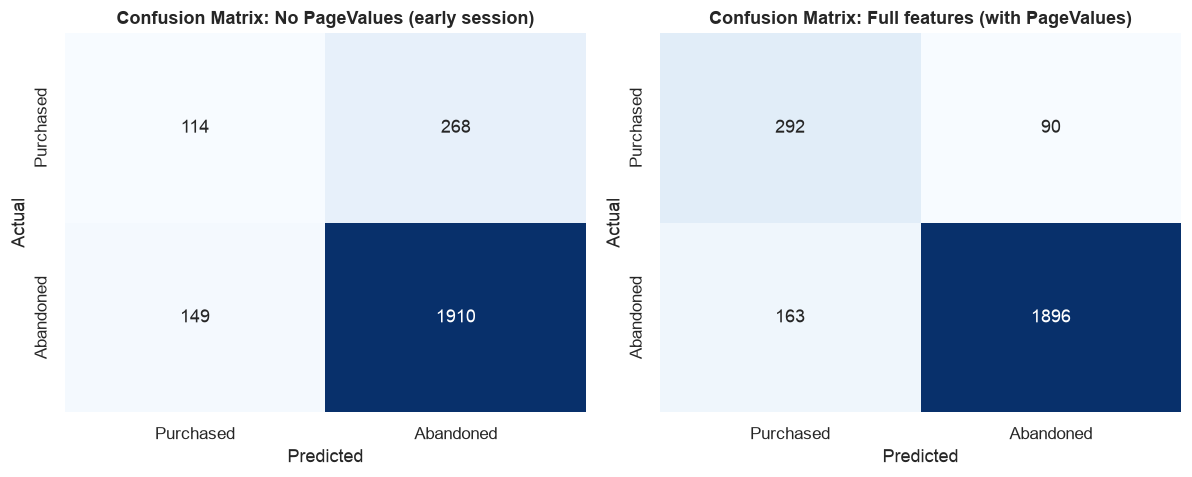

In [15]:
# Plot confusion matrices for both tuned model variants at optimal threshold t*
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, key, title in zip(axes, ['no_pagevalues', 'with_pagevalues'], ['No PageValues (early session)', 'Full features (with PageValues)']):
    cm = np.array([[final[key]['at_threshold']['tn'], final[key]['at_threshold']['fp']],
                   [final[key]['at_threshold']['fn'], final[key]['at_threshold']['tp']]])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Purchased', 'Abandoned'], yticklabels=['Purchased', 'Abandoned'])
    ax.set_title(f'Confusion Matrix: {title}', weight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')

plt.tight_layout()
savefig('05_confusion_matrix.png')
plt.show()


### 8.1 Model Explainability & Error Analysis (SHAP)
> **Faculty Explanation Note:**
> SHAP (SHapley Additive exPlanations) TreeExplainer computes exact log-odds feature contributions, opening the 'black box' of Gradient Boosting to show which session behaviors drive abandonment risk.

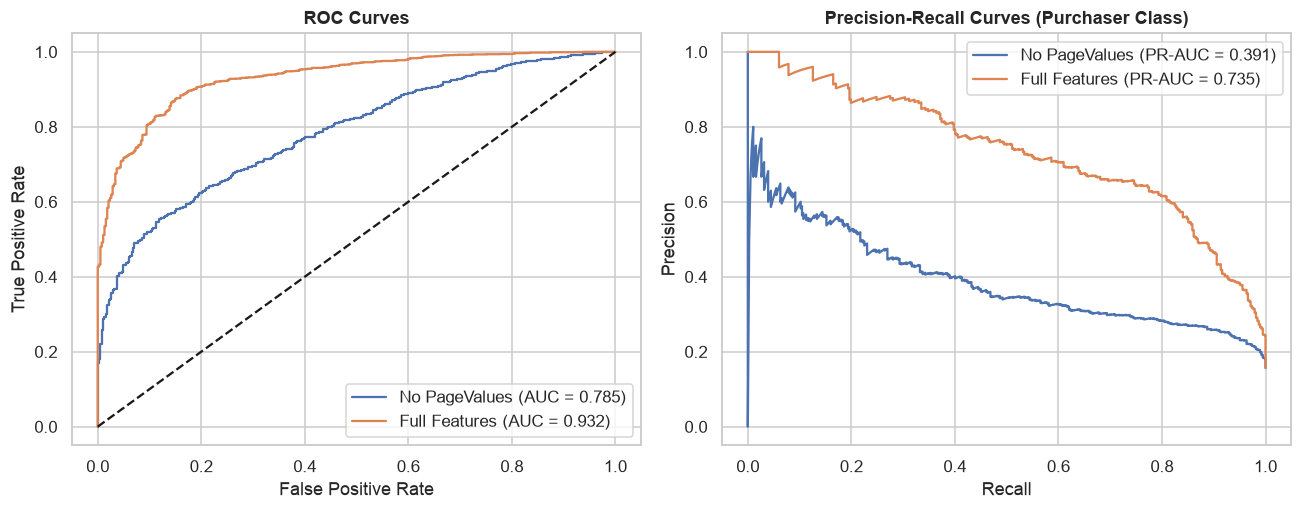

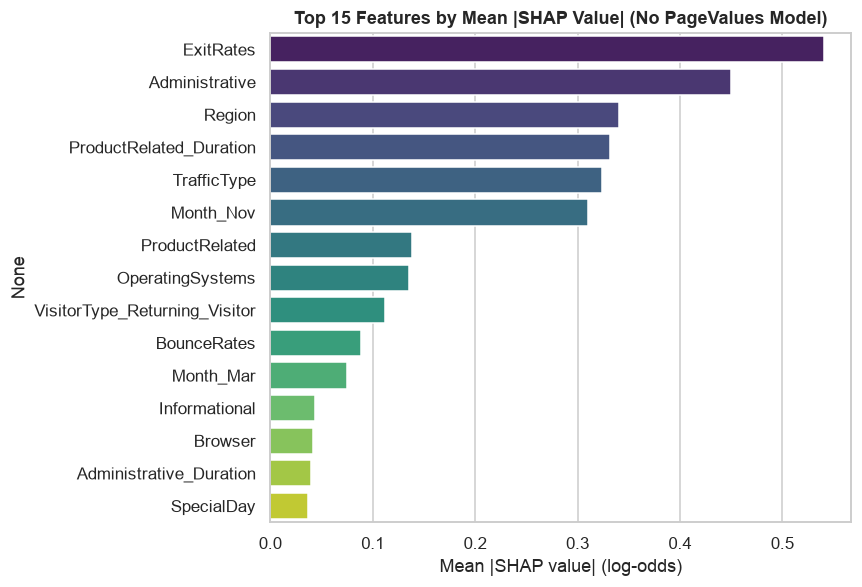

Top drivers: ExitRates, Administrative, Region, ProductRelated_Duration, TrafficType


In [16]:
# Plot ROC and Precision-Recall curves comparing early-session and full model performance
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Compute ROC curves for test set predictions
fpr_r, tpr_r, _ = roc_curve(y_test, prob_test_no_pv)
fpr_f, tpr_f, _ = roc_curve(y_test, prob_test_full)
axes[0].plot(fpr_r, tpr_r, label=f'No PageValues (AUC = {final["no_pagevalues"]["at_threshold"]["ROC-AUC"]:.3f})')
axes[0].plot(fpr_f, tpr_f, label=f'Full Features (AUC = {final["with_pagevalues"]["at_threshold"]["ROC-AUC"]:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title('ROC Curves', weight='bold'); axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate'); axes[0].legend()

# Compute Precision-Recall curves for purchaser class
prec_r, rec_r, _ = precision_recall_curve(1 - y_test, 1 - prob_test_no_pv)
prec_f, rec_f, _ = precision_recall_curve(1 - y_test, 1 - prob_test_full)
axes[1].plot(rec_r, prec_r, label=f'No PageValues (PR-AUC = {final["no_pagevalues"]["at_threshold"]["PR-AUC (Purchaser)"]:.3f})')
axes[1].plot(rec_f, prec_f, label=f'Full Features (PR-AUC = {final["with_pagevalues"]["at_threshold"]["PR-AUC (Purchaser)"]:.3f})')
axes[1].set_title('Precision-Recall Curves (Purchaser Class)', weight='bold'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].legend()

plt.tight_layout()
savefig('06_roc_pr_curves.png')
plt.show()

# Calculate global SHAP feature importance values for early-session model
pre_f, gbm = tuned_no_pv.named_steps['preprocessor'], tuned_no_pv.named_steps['model']
Xt = pre_f.transform(X_test_real)
Xt = Xt.toarray() if hasattr(Xt, 'toarray') else Xt
names = [n.split('__', 1)[-1] for n in pre_f.get_feature_names_out()]
sv = shap.TreeExplainer(gbm).shap_values(Xt)
imp = pd.Series(np.abs(sv).mean(axis=0), index=names).sort_values(ascending=False).head(15)

# Plot top 15 features ranked by mean absolute SHAP value
plt.figure(figsize=(8, 5.5))
sns.barplot(x=imp.values, y=imp.index, palette='viridis')
plt.title('Top 15 Features by Mean |SHAP Value| (No PageValues Model)', weight='bold')
plt.xlabel('Mean |SHAP value| (log-odds)')
plt.tight_layout()
savefig('08_shap_summary.png')
plt.show()
print("Top drivers:", ", ".join(imp.index[:5]))


## 9. Unsupervised Behavioral Segmentation (569XMeans Personas)
> **Faculty Explanation Note:**
> 569XMeans clustering (=3$) on log-transformed session duration and bounce/exit metrics of abandoners creates 3 distinct personas (*Light Browsers*, *Bouncers*, *Deep Browsers*) to automate targeted intervention logic.

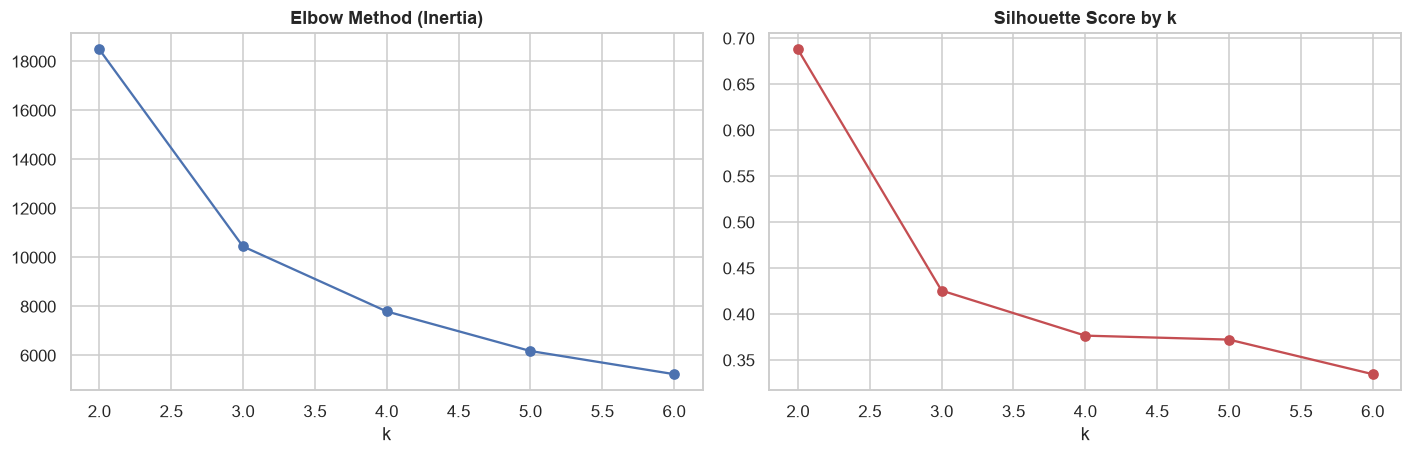

,k,Inertia,Silhouette
0,2,18492.4,0.688
1,3,10450.1,0.426
2,4,7796.9,0.377
3,5,6181.4,0.372
4,6,5236.6,0.335


In [17]:
# Select abandoning sessions and log-transform behavioral duration metrics
abandoners = df[df['Is_Abandoned'] == 1].copy()
cluster_features = ['ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates']
cluster_scaler = StandardScaler()
Xc = cluster_scaler.fit_transform(np.log1p(abandoners[cluster_features]))

# Sweep cluster count k from 2 to 6 to evaluate inertia and silhouette scores
ks = list(range(2, 7))
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Xc)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xc, km.labels_))

# Plot Elbow curve and Silhouette score curve across k
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(ks, inertias, 'bo-')
axes[0].set_title('Elbow Method (Inertia)', weight='bold'); axes[0].set_xlabel('k')
axes[1].plot(ks, sils, 'ro-')
axes[1].set_title('Silhouette Score by k', weight='bold'); axes[1].set_xlabel('k')

plt.tight_layout()
savefig('09_k_sweep.png')
plt.show()

# Display cluster sweep diagnostic table
display(pd.DataFrame({'k': ks, 'Inertia': np.round(inertias, 1), 'Silhouette': np.round(sils, 3)}))


,Cluster,Persona,Session_Count,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,Share (%)
0,0,Light Browsers,4207,8.059,261.827,0.015,0.049,40.86
1,1,Bouncers,738,2.148,19.323,0.181,0.190,7.17
2,2,Deep Browsers,5352,49.261,1875.121,0.008,0.023,51.98


Silhouette at k=3: 0.426


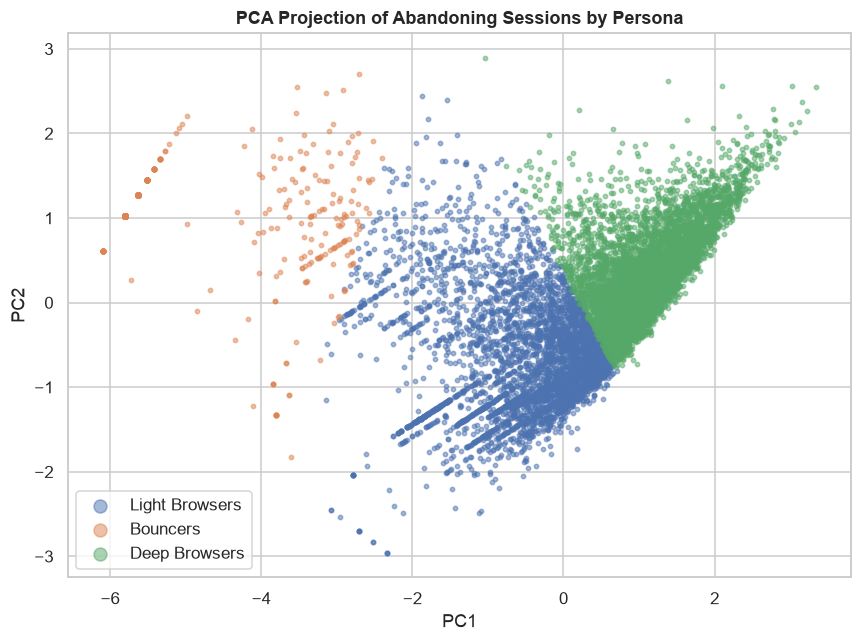

In [18]:
# Fit final K-Means model with optimal k=3 clusters
K_FINAL = 3
kmeans = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=10).fit(Xc)
abandoners['Cluster'] = kmeans.labels_
means = abandoners.groupby('Cluster')[cluster_features].mean()

# Map data-driven customer personas based on feature means
bounce_c, deep_c = means['BounceRates'].idxmax(), means['ProductRelated'].idxmax()
assert bounce_c != deep_c, "Clusters not separable into bouncer/deep-browser personas"
light_c = ({0, 1, 2} - {bounce_c, deep_c}).pop()
persona_map = {bounce_c: 'Bouncers', deep_c: 'Deep Browsers', light_c: 'Light Browsers'}
abandoners['Persona'] = abandoners['Cluster'].map(persona_map)

# Construct cluster profiles table showing persona shares and feature averages
cluster_profiles = means.copy()
cluster_profiles.insert(0, 'Persona', cluster_profiles.index.map(persona_map))
cluster_profiles.insert(1, 'Session_Count', abandoners['Cluster'].value_counts().sort_index())
cluster_profiles['Share (%)'] = (cluster_profiles['Session_Count'] / len(abandoners) * 100).round(2)
cluster_profiles = cluster_profiles.reset_index().sort_values('Cluster')
display(cluster_profiles.round(3))
print(f"Silhouette at k={K_FINAL}: {silhouette_score(Xc, kmeans.labels_):.3f}")

# Reduce feature dimensions to 2D using PCA for cluster visualization
pca = PCA(n_components=2, random_state=SEED)
pts = pca.fit_transform(Xc)

# Plot 2D PCA scatter plot of abandoner personas
plt.figure(figsize=(8, 6))
for c in sorted(persona_map):
    mask = (kmeans.labels_ == c)
    plt.scatter(pts[mask, 0], pts[mask, 1], s=8, alpha=.5, label=persona_map[c])
plt.title('PCA Projection of Abandoning Sessions by Persona', weight='bold')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend(markerscale=3)
plt.tight_layout()
savefig('10_pca_clusters.png')
plt.show()


## 10. Artifact Export & Streamlit Web App Integration
> **Faculty Explanation Note:**
> Serializes trained pipelines (), metric summaries (), and benchmark CSVs to  and  for consumption by the interactive Streamlit dashboard.

In [19]:
# Save trained pipeline models and cluster scaler objects using joblib
joblib.dump(tuned_no_pv, os.path.join(MODELS_DIR, 'model_no_pagevalues.joblib'))
joblib.dump(tuned_full,  os.path.join(MODELS_DIR, 'model_with_pagevalues.joblib'))
joblib.dump(kmeans,      os.path.join(MODELS_DIR, 'kmeans_cluster_model.joblib'))
joblib.dump(cluster_scaler, os.path.join(MODELS_DIR, 'cluster_scaler.joblib'))

# Export experiment results, sensitivity table, and cluster profiles to CSV
exp_df = pd.DataFrame(experiment_rows)
for c in exp_df.columns[3:]:
    exp_df[c] = exp_df[c].astype(float).round(4 if c in ('ROC-AUC', 'PR-AUC (Purchaser)') else 2)

exp_df.to_csv(os.path.join(REPORTS_DIR, 'experiment_results.csv'), index=False)
sens_df.to_csv(os.path.join(REPORTS_DIR, 'cost_sensitivity.csv'), index=False)
cluster_profiles.round(4).to_csv(os.path.join(REPORTS_DIR, 'cluster_profiles.csv'), index=False)

# Helper function to package test metrics for Streamlit app
def pack(key, params, t):
    m = dict(final[key]['at_threshold'])
    out = {'threshold': t, 'roc_auc': m['ROC-AUC'], 'pr_auc': m['PR-AUC (Purchaser)'], 'abandoner_f1': m['Abandoner F1 (%)'] / 100,
           'purchaser_f1': m['Purchaser F1 (%)'] / 100, 'macro_f1': m['Macro F1 (%)'] / 100, 'accuracy': m['Accuracy (%)'] / 100,
           'fpr': m['FPR (%)'] / 100, 'tn': m['tn'], 'fp': m['fp'], 'fn': m['fn'], 'tp': m['tp'], 'best_params': params}
    a = final[key]['at_0_5']
    out['at_0_5'] = {'abandoner_f1': a['Abandoner F1 (%)'] / 100, 'purchaser_f1': a['Purchaser F1 (%)'] / 100,
                     'macro_f1': a['Macro F1 (%)'] / 100, 'accuracy': a['Accuracy (%)'] / 100, 'fpr': a['FPR (%)'] / 100}
    return out

# Export metrics JSON file for interactive web app consumption
primary_row = sens_df[sens_df['FN Cost ($)'] == PRIMARY_C_FN].iloc[0]
metrics_json = {
    'optimal_threshold': t_no_pv,
    'base_abandonment_rate': float(base_abandonment_rate),
    'n_sessions': int(len(df)), 'n_train': int(len(X_train)), 'n_test': int(len(X_test)),
    'cost_fp': C_FP, 'primary_cost_fn': PRIMARY_C_FN,
    'primary_cost_saving_pct': float(primary_row['Savings vs Best Naive (%)']),
    'cost_assumption_note': 'C_FN is the expected recovered margin per missed abandoner; C_FP is the coupon cost.',
    'no_pagevalues_model':   pack('no_pagevalues',   gs_real.best_params_, t_no_pv),
    'with_pagevalues_model': pack('with_pagevalues', gs_full.best_params_, t_full),
}

with open(os.path.join(REPORTS_DIR, 'test_evaluation_metrics.json'), 'w') as f:
    json.dump(metrics_json, f, indent=2, default=float)

print("Models  :", sorted(os.listdir(MODELS_DIR)))
print("Reports :", sorted(x for x in os.listdir(REPORTS_DIR) if x != 'figures'))
print("Figures :", sorted(os.listdir(FIG_DIR)))


Models  : ['cluster_scaler.joblib', 'kmeans_cluster_model.joblib', 'model_no_pagevalues.joblib', 'model_with_pagevalues.joblib']
Reports : ['cluster_profiles.csv', 'cost_sensitivity.csv', 'experiment_results.csv', 'test_evaluation_metrics.json', 'viva_preparation_guide.md']
Figures : ['01_eda_categorical.png', '01_target_month_visitor.png', '02_behaviour_boxplots.png', '02_eda_boxplots.png', '03_correlation.png', '03_correlation_matrix.png', '05_confusion_matrix.png', '06_roc_pr_curves.png', '07_threshold_cost_analysis.png', '08_shap_summary.png', '09_k_sweep.png', '10_pca_clusters.png']


## 11. Comprehensive Project Summary & Future Scope
*Summary table comparing early-session vs full models, key business takeaways, and model limitations for academic defense.*

In [20]:
# Render summary table and final academic takeaways
n = metrics_json['no_pagevalues_model']; w = metrics_json['with_pagevalues_model']
display(Markdown(f'''
**Key results (test set, tuned Gradient Boosting)**

| Model | ROC-AUC | PR-AUC (purchasers) | Purchaser F1 | Macro F1 | Threshold t* |
|---|---|---|---|---|---|
| Full features (with PageValues) | {w['roc_auc']:.3f} | {w['pr_auc']:.3f} | {w['purchaser_f1']:.3f} | {w['macro_f1']:.3f} | {w['threshold']:.2f} |
| Early session (no PageValues)   | {n['roc_auc']:.3f} | {n['pr_auc']:.3f} | {n['purchaser_f1']:.3f} | {n['macro_f1']:.3f} | {n['threshold']:.2f} |

- Removing `PageValues` lowers ROC-AUC from {w['roc_auc']:.3f} to {n['roc_auc']:.3f}: behaviour alone predicts purchase only moderately.
- Cost analysis: at C_FN=${PRIMARY_C_FN:g} / C_FP=${C_FP:g} the tuned threshold saves {metrics_json['primary_cost_saving_pct']:.1f}% versus the best naive strategy.

**Limitations**
1. **Session non-conversion, not cart events.** There is no add-to-cart signal, so "abandonment" means "did not buy".
2. **`PageValues` is a near-proxy** for the target and is unavailable early in a session. The early-session model is the realistic one.
3. **Cost values are assumptions.** The $ figures are illustrative; the sensitivity table shows where the model stops being useful.
4. **SMOTE shifts predicted probabilities** (training is class-balanced), so probabilities are not calibrated to the true 84% base rate.
5. **Snapshot data, session-level only:** no user history or event sequence.
6. Clusters are fitted on all abandoning sessions (unsupervised, exploratory), so cluster membership was not validated on a held-out set.
'''))



**Key results (test set, tuned Gradient Boosting)**

| Model | ROC-AUC | PR-AUC (purchasers) | Purchaser F1 | Macro F1 | Threshold t* |
|---|---|---|---|---|---|
| Full features (with PageValues) | 0.932 | 0.735 | 0.698 | 0.818 | 0.47 |
| Early session (no PageValues)   | 0.785 | 0.391 | 0.353 | 0.628 | 0.53 |

- Removing `PageValues` lowers ROC-AUC from 0.932 to 0.785: behaviour alone predicts purchase only moderately.
- Cost analysis: at C_FN=$1 / C_FP=$2 the tuned threshold saves 7.9% versus the best naive strategy.

**Limitations**
1. **Session non-conversion, not cart events.** There is no add-to-cart signal, so "abandonment" means "did not buy".
2. **`PageValues` is a near-proxy** for the target and is unavailable early in a session. The early-session model is the realistic one.
3. **Cost values are assumptions.** The $ figures are illustrative; the sensitivity table shows where the model stops being useful.
4. **SMOTE shifts predicted probabilities** (training is class-balanced), so probabilities are not calibrated to the true 84% base rate.
5. **Snapshot data, session-level only:** no user history or event sequence.
6. Clusters are fitted on all abandoning sessions (unsupervised, exploratory), so cluster membership was not validated on a held-out set.
